# Turtle Breakout 04 — what separates winning from losing trades of the original turtle?

Pre-registration: `discussions/Turtle_Breakout/006_claude_tb04_preregistration.md`. Code: `src/data_engineering/modeling/turtle_trade_features.py`.

Original rules (TB 01) on ~30 Binance USD-M USDT perpetuals. **Discovery**: 26 non-core perps, full history. **Confirmation**: BTC/ETH/SOL/XRP from 2020-10-15 (the TB 01 trades).
Label: $R$ = net return / (2 ATR / entry), win = $R>0$. Entry features (price, flow/CVD, funding, volatility engine, open interest and positioning, spot–perp basis, market breadth) are known before the entry bar; path features are measured during the trade and are descriptive only.

Environment: `TB01_DATA_DIR` (default `BINANCE_UM_DIR\long`), `TB04_SYNTHETIC=1`.

In [1]:
import os, sys, json, time, gc, subprocess, tempfile, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 120)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_trade_features as tf, vwap_drift as vd

SYNTHETIC = os.getenv('TB04_SYNTHETIC', '0') == '1'
P = tb.Params(); FP = tf.FParams()
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb04-')) / '04'; FP = tf.FParams(n_boot=300, n_perm=40)
    ASSETS = ['BTC', 'ETH', 'SOL', 'XRP', 'BNB', 'DOGE', 'ADA', 'LINK', 'DOT', 'LTC']
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '04'
    base = Path(os.environ['BINANCE_UM_DIR']) if os.environ.get('BINANCE_UM_DIR') else Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance'
    DATA = Path(os.environ.get('TB01_DATA_DIR', str(base / 'long')))
    ASSETS = list(tf.UNIVERSE)
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_turtle_trade_features.py'], cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0
FITS = vd.load_engine(ROOT / 'notebooks' / 'Volatility_Dynamics' / '18' / '18_manifest.json')
print(json.dumps(tf.registration(FP), indent=1)[:2500])

OK
{
 "fdr_q": 0.1,
 "confirm_alpha": 0.05,
 "n_boot": 2000,
 "n_perm": 200,
 "ridge": 1.0,
 "min_feature_n": 100,
 "seed": 20261027,
 "status": "PREREGISTERED_TB006",
 "version": "TB04-0.1.0",
 "confirm_assets": [
  "BTC",
  "ETH",
  "SOL",
  "XRP"
 ],
 "discovery_assets": [
  "BNB",
  "DOGE",
  "ADA",
  "LINK",
  "DOT",
  "LTC",
  "BCH",
  "UNI",
  "NEAR",
  "APT",
  "ARB",
  "OP",
  "SUI",
  "FIL",
  "ATOM",
  "ETC",
  "INJ",
  "AAVE",
  "TON",
  "WIF",
  "HBAR",
  "XLM",
  "SEI",
  "TIA",
  "ENA",
  "WLD"
 ],
 "entry_features": {
  "price": [
   "brk_gap_atr",
   "move_to_level_atr",
   "atr_pct",
   "atr_rel_100",
   "range20_atr",
   "ret20_atr",
   "ret60_log",
   "dist_ma50_atr",
   "dist_ma200_atr",
   "above_ma200",
   "days_since_prev_break",
   "entry_day_frac",
   "prev_trade_win",
   "consec_losses"
  ],
  "flow": [
   "vol24_rel",
   "vol1h_rel",
   "tbr_1h",
   "tbr_24h",
   "cvd4h_norm",
   "trades24_rel",
   "trade_size_rel"
  ],
  "funding": [
   "fund_last_bp",
   "

## 1. Trades and features, asset by asset

In [2]:
T0 = time.time(); FS, STATES, COV = [], [], []
for i, a in enumerate(ASSETS):
    t1 = time.time()
    if SYNTHETIC:
        b = tb.synthetic_5m(1800, seed=60 + i, trend=0.01, start='2020-01-01'); x = tf.synthetic_flow(b, i)
        f = tb.synthetic_funding(b, 0.0001); f['rate'] *= 1 + 0.5 * np.sin(np.arange(len(f)) / 30)
        rng = np.random.default_rng(i)
        met = pd.DataFrame({'sum_open_interest': np.exp(np.cumsum(rng.normal(0, .01, len(b) // 12))) * 1e6}, index=b.index[::12][:len(b) // 12])
        met['sum_open_interest_value'] = met.sum_open_interest * 100
        for c in ('sum_toptrader_long_short_ratio', 'count_long_short_ratio', 'sum_taker_long_short_vol_ratio'): met[c] = 1 + rng.normal(0, .05, len(met))
        spot = b.close * (1 - 0.0002 * (1 + rng.normal(0, .5, len(b))))
    else:
        pu = DATA / f'{a}USDT_um_1m.parquet'
        if not pu.exists():
            COV.append({'asset': a, 'status': 'no perp file'}); print(a, 'missing'); continue
        b, x = tf.load_um(pu)
        fpth = DATA / 'basis' / 'funding' / f'{a}USDT_funding.parquet'
        f = tb.funding_events(pd.read_parquet(fpth)) if fpth.exists() else None
        spot = tf.load_spot_close(DATA / 'basis' / 'spot' / f'{a}USDT_spot_1m.parquet')
        met = tf.load_metrics(DATA / 'basis' / 'metrics' / f'{a}USDT_metrics.parquet')
    d = tb.prepare_asset(a, b, f, P)
    start = tb.COMMON_START if a in tf.CONFIRM_ASSETS else b.index[0] + pd.Timedelta(days=30)
    T = tf.run_trades(d, P, start)
    F = tf.entry_and_path_features(a, d, x, T, f, spot, met, FITS)
    if len(F):
        F['set'] = 'confirm' if a in tf.CONFIRM_ASSETS else 'discovery'; FS.append(F)
    STATES.append(tf.daily_states(a, d))
    COV.append({'asset': a, 'status': 'ok', 'first_bar': b.index[0], 'last_bar': b.index[-1], 'trades': len(T),
                'win_rate': float(T.win.mean()) if len(T) else np.nan, 'sum_R': float(T.R.sum()) if len(T) else 0.0,
                'funding': f is not None, 'spot': spot is not None, 'metrics': met is not None,
                'metrics_first': None if met is None else met.index[0]})
    print(f"{a}: {len(T)} trades, {time.time() - t1:.0f}s")
    del b, x, d, spot, met; gc.collect()
COV = pd.DataFrame(COV); display(COV)
FALL = tf.add_market_features(pd.concat(FS, ignore_index=True), pd.concat(STATES, ignore_index=True))
Fd, Fc = FALL[FALL.set == 'discovery'].reset_index(drop=True), FALL[FALL.set == 'confirm'].reset_index(drop=True)
print('discovery', len(Fd), 'trades, win rate', round(Fd.win.mean(), 3), '| confirmation', len(Fc), 'trades, win rate', round(Fc.win.mean(), 3))
ENTRY = [c for g in tf.ENTRY_FEATURES.values() for c in g]
GROUP = {c: g for g, cs in tf.ENTRY_FEATURES.items() for c in cs}
display(FALL.groupby('set')[ENTRY].apply(lambda g: g.notna().mean()).T.round(2))

BTC: 49 trades, 7s
ETH: 44 trades, 5s
SOL: 46 trades, 4s
XRP: 41 trades, 5s
BNB: 55 trades, 5s
DOGE: 44 trades, 5s
ADA: 51 trades, 5s
LINK: 58 trades, 5s
DOT: 45 trades, 4s
LTC: 54 trades, 5s
BCH: 52 trades, 4s
UNI: 46 trades, 4s
NEAR: 44 trades, 4s
APT: 32 trades, 3s
ARB: 26 trades, 3s
OP: 34 trades, 3s
SUI: 28 trades, 3s
FIL: 41 trades, 4s
ATOM: 52 trades, 5s
ETC: 50 trades, 5s
INJ: 34 trades, 3s
AAVE: 52 trades, 4s
TON: 116 trades, 2s
WIF: 19 trades, 2s
HBAR: 33 trades, 4s
XLM: 53 trades, 5s
SEI: 22 trades, 2s
TIA: 24 trades, 2s
ENA: 20 trades, 2s
WLD: 26 trades, 3s


,asset,status,first_bar,last_bar,trades,win_rate,sum_R,funding,spot,metrics,metrics_first
0,BTC,ok,2020-01-01 00:05:00+00:00,2026-10-24 00:00:00+00:00,49,0.387755,35.858903,True,True,True,2021-12-01 00:00:00+00:00
1,ETH,ok,2020-01-01 00:05:00+00:00,2026-10-24 00:00:00+00:00,44,0.454545,29.657670,True,True,True,2021-12-01 00:00:00+00:00
2,SOL,ok,2020-09-14 07:05:00+00:00,2026-10-24 00:00:00+00:00,46,0.434783,59.898002,True,True,True,2021-12-01 00:00:00+00:00
3,XRP,ok,2020-01-06 08:25:00+00:00,2026-10-24 00:00:00+00:00,41,0.341463,71.415046,True,True,True,2021-12-01 00:00:00+00:00
4,BNB,ok,2020-02-10 08:05:00+00:00,2026-10-24 00:00:00+00:00,55,0.418182,40.237476,True,True,True,2021-12-01 00:00:00+00:00
5,DOGE,ok,2020-07-10 09:05:00+00:00,2026-10-24 00:00:00+00:00,44,0.409091,69.839505,True,True,True,2021-12-01 00:00:00+00:00
6,ADA,ok,2020-01-31 08:05:00+00:00,2026-10-24 00:00:00+00:00,51,0.274510,54.222574,True,True,True,2021-12-01 00:00:00+00:00
7,LINK,ok,2020-01-17 08:05:00+00:00,2026-10-24 00:00:00+00:00,58,0.310345,10.442060,True,True,True,2021-12-01 00:00:00+00:00
8,DOT,ok,2020-08-22 07:05:00+00:00,2026-10-24 00:00:00+00:00,45,0.288889,11.504475,True,True,True,2021-12-01 00:00:00+00:00
9,LTC,ok,2020-01-09 08:10:00+00:00,2026-10-24 00:00:00+00:00,54,0.259259,-11.272494,True,True,True,2021-12-01 00:00:00+00:00


discovery 1111 trades, win rate 0.284 | confirmation 180 trades, win rate 0.406


set,confirm,discovery
brk_gap_atr,1.00,1.00
move_to_level_atr,1.00,1.00
atr_pct,1.00,1.00
atr_rel_100,0.99,0.98
range20_atr,1.00,1.00
ret20_atr,1.00,1.00
ret60_log,1.00,1.00
dist_ma50_atr,1.00,0.99
dist_ma200_atr,0.98,0.91
above_ma200,0.98,0.91


## 2. Pre-registered univariate screen (discovery, BH-FDR) and confirmation (Holm)

In [3]:
Ud = tf.univariate(Fd, ENTRY, 'win', FP); Ud['group'] = Ud.feature.map(GROUP)
display(Ud.sort_values('p').round(4))
CONF = tf.confirm(Ud, Fc, 'win', FP)
print(f"discovery survivors (q < {FP.fdr_q}):", int((Ud.q_bh < FP.fdr_q).sum()))
display(CONF.round(4))

,feature,n,auc,lo,hi,p,spearman_R,median_win,median_loss,q_bh,group
21,fund_last_bp,1111,0.4204,0.3560,0.4908,0.028,-0.1079,1.0000,1.0000,0.4141,funding
23,fund_z30,1108,0.4294,0.3624,0.4956,0.035,-0.0609,0.3300,0.4225,0.4141,funding
10,days_since_prev_break,1096,0.5748,0.4953,0.6464,0.066,0.1050,30.0000,27.0000,0.4141,price
26,rv24_over_atr,1111,0.5850,0.4923,0.6639,0.072,-0.0639,0.7633,0.6867,0.4141,engine
38,btc_ret20_log,1109,0.5643,0.4943,0.6300,0.083,0.0553,0.0615,0.0506,0.4141,market
4,range20_atr,1111,0.5625,0.4885,0.6315,0.089,-0.0407,3.3924,3.2373,0.4141,price
1,move_to_level_atr,1111,0.5671,0.4895,0.6293,0.090,-0.0405,0.7295,0.6384,0.4141,price
27,jump24_sig,1111,0.5664,0.4871,0.6390,0.097,-0.0188,4.3482,4.1159,0.4141,engine
29,oi_chg_7d,814,0.4554,0.4032,0.5105,0.114,-0.0761,0.0405,0.0665,0.4141,oi
20,trade_size_rel,1009,0.5384,0.4901,0.5909,0.126,0.0019,1.0282,1.0158,0.4141,flow


discovery survivors (q < 0.1): 0


,feature,auc_disc,auc_conf,p_one_sided,holm_threshold,confirmed


## 3. Pre-registered model test: ridge logistic on all entry features

In [4]:
MOD = tf.model_test(Fd, Fc, ENTRY, 'win', FP)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in MOD.items() if k not in ('coef', 'scores_confirm', 'features')})
display(pd.Series(MOD['coef']).head(15).round(3))
ECON = tf.tercile_economics(Fc, MOD['scores_confirm']); print('Reported only: confirmation trades by model-score tercile'); display(ECON.round(3))
DECISION = {'n_discovery': len(Fd), 'n_confirm': len(Fc), 'discovery_survivors': int((Ud.q_bh < FP.fdr_q).sum()),
            'confirmed_features': CONF.loc[CONF.confirmed, 'feature'].tolist() if len(CONF) else [],
            'model_auc_confirm': MOD['auc_confirm'], 'model_lo': MOD['lo'], 'model_perm_p': MOD['perm_p'], 'model_passed': MOD['passed']}
DECISION['verdict'] = 'ENTRY_SIGNAL_CONFIRMED' if (DECISION['confirmed_features'] or MOD['passed']) else 'NOTHING_CONFIRMED'
print(json.dumps(DECISION, indent=1, default=float))

{'auc_discovery_insample': 0.7238, 'auc_confirm': 0.6052, 'lo': 0.5107, 'hi': 0.698, 'perm_p': 0.0149, 'perm_null_q95': 0.5755, 'passed': True}


fund_last_bp      -0.669
vol24_rel          0.585
consec_losses      0.482
btc_ret20_log      0.446
fund_3d_bp        -0.335
basis_24h_bp       0.320
trades24_rel      -0.256
ret20_atr         -0.256
eng_sig60_rel30   -0.247
entry_day_frac    -0.241
taker_ls_24h       0.198
basis_bp          -0.196
oi_chg_7d         -0.184
atr_rel_100        0.182
dist_ma50_atr      0.159
dtype: float64

Reported only: confirmation trades by model-score tercile


,trades,win_rate,mean_R,sum_R,median_R,big
tercile,,,,,,
high,60,0.550,2.308,138.481,0.142,14
low,60,0.400,0.974,58.465,-0.241,7
mid,60,0.267,-0.002,-0.116,-0.504,3


{
 "n_discovery": 1111,
 "n_confirm": 180,
 "discovery_survivors": 0,
 "confirmed_features": [],
 "model_auc_confirm": 0.6051721930610677,
 "model_lo": 0.5107083164126787,
 "model_perm_p": 0.014925373134328358,
 "model_passed": true,
 "verdict": "ENTRY_SIGNAL_CONFIRMED"
}


## 4. Reported: big winners (R ≥ 3), per-group models

In [5]:
Ub = tf.univariate(Fd, ENTRY, 'big', FP, seed0=1000); Ub['group'] = Ub.feature.map(GROUP)
CONFb = tf.confirm(Ub, Fc, 'big', FP)
display(Ub.sort_values('p').head(12).round(4)); display(CONFb.round(4))
grp = []
for g, cs in tf.ENTRY_FEATURES.items():
    m = tf.model_test(Fd, Fc, cs, 'win', tf.FParams(n_boot=FP.n_boot, n_perm=50, min_feature_n=FP.min_feature_n))
    grp.append({'group': g, 'features': len(m['features']), 'auc_confirm': m['auc_confirm'], 'lo': m['lo'], 'hi': m['hi'], 'perm_p': m['perm_p']})
GRP = pd.DataFrame(grp); display(GRP.round(3))

,feature,n,auc,lo,hi,p,spearman_R,median_win,median_loss,q_bh,group
26,rv24_over_atr,1111,0.6237,0.5259,0.7074,0.012,-0.0639,0.8036,0.6999,0.1867,engine
24,eng_sig1d_over_atr,1111,0.6105,0.5251,0.6920,0.013,-0.0750,0.8336,0.7481,0.1867,engine
6,ret60_log,1111,0.6302,0.5327,0.7231,0.014,-0.0884,0.0996,-0.0253,0.1867,price
25,eng_sig60_rel30,1111,0.5863,0.5141,0.6502,0.020,-0.0523,1.4299,1.3061,0.2000,engine
7,dist_ma50_atr,1102,0.6119,0.4992,0.7313,0.054,-0.0845,1.6138,0.8112,0.2907,price
36,basis_24h_bp,1005,0.5800,0.4965,0.6609,0.059,-0.0733,-0.6597,-4.0419,0.2907,basis
35,basis_bp,1005,0.5846,0.4952,0.6649,0.063,-0.0561,3.1908,-2.3669,0.2907,basis
39,btc_in_breakout,1111,0.5468,0.4940,0.5996,0.074,0.0376,0.0000,0.0000,0.2907,market
1,move_to_level_atr,1111,0.5659,0.4920,0.6443,0.077,-0.0405,0.7390,0.6482,0.2907,price
23,fund_z30,1108,0.4321,0.3551,0.5094,0.083,-0.0609,0.2880,0.4064,0.2907,funding


,feature,auc_disc,auc_conf,p_one_sided,holm_threshold,confirmed


,group,features,auc_confirm,lo,hi,perm_p
0,price,14,0.562,0.467,0.659,0.078
1,flow,7,0.585,0.501,0.673,0.020
2,funding,3,0.567,0.475,0.656,0.020
3,engine,4,0.533,0.437,0.631,0.353
4,oi,7,0.546,0.447,0.641,0.235
5,basis,3,0.435,0.331,0.547,0.961
6,market,3,0.467,0.372,0.550,0.608


## 5. Inside the trades (descriptive): path features and early-path win rates

In [6]:
PT = pd.concat([tf.path_table(Fd).assign(set='discovery'), tf.path_table(Fc).assign(set='confirm')])
display(PT.round(3))
EP = pd.concat([tf.early_path_table(Fd).assign(set='discovery'), tf.early_path_table(Fc).assign(set='confirm')])
display(EP.round(3))
print('exit reasons by outcome'); display(pd.crosstab([FALL.set, FALL.reason], FALL.win))

,feature,n,median_win,median_loss,auc_descriptive,set
0,mfe_R,1111,4.098,0.458,0.971,discovery
1,mae_R,1111,0.264,0.839,0.222,discovery
2,days_to_mfe,1111,17.326,0.885,0.930,discovery
3,R_1d,983,0.308,-0.043,0.712,discovery
4,R_3d,907,0.613,-0.081,0.787,discovery
5,R_5d,811,0.899,-0.059,0.840,discovery
6,tbr_first24h,1009,0.493,0.489,0.596,discovery
7,tbr_first72h,1009,0.492,0.487,0.618,discovery
8,vol_first3d_rel,1111,1.915,1.310,0.685,discovery
9,oi_chg_first3d,815,0.009,-0.024,0.596,discovery


,day,bucket,trades,win_rate,mean_final_R,set
0,R_1d,"(-inf, -0.5]",53,0.113,-0.687,discovery
1,R_1d,"(-0.5, -0.25]",152,0.184,-0.160,discovery
2,R_1d,"(-0.25, 0.0]",244,0.193,-0.040,discovery
3,R_1d,"(0.0, 0.25]",221,0.285,0.271,discovery
4,R_1d,"(0.25, 0.5]",144,0.451,0.706,discovery
5,R_1d,"(0.5, 1.0]",105,0.600,1.899,discovery
6,R_1d,"(1.0, inf]",64,0.672,2.949,discovery
7,R_3d,"(-inf, -0.5]",106,0.038,-0.576,discovery
8,R_3d,"(-0.5, -0.25]",133,0.180,-0.385,discovery
9,R_3d,"(-0.25, 0.0]",147,0.177,-0.038,discovery


exit reasons by outcome


win                           0    1
set       reason                    
confirm   fixed_stop         40    0
          trail              67   73
discovery fixed_stop        233    0
          stop_same_period  118    0
          trail             445  315

## 6. Figures

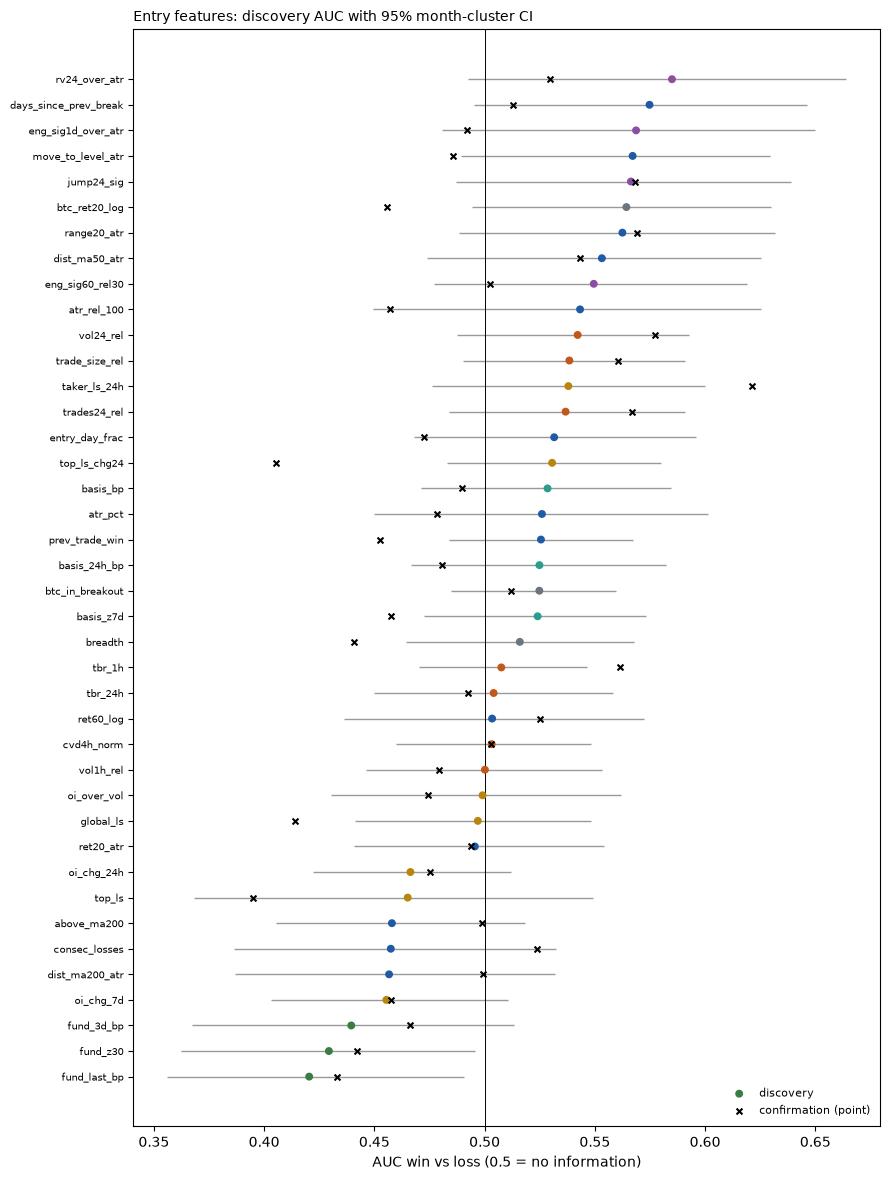

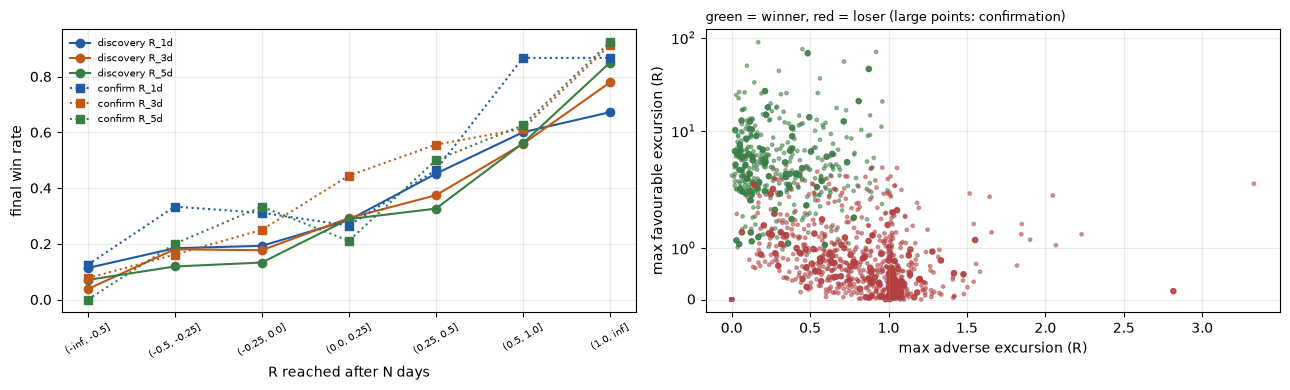

In [7]:
U = Ud.dropna(subset=['auc']).sort_values('auc')
cmap = dict(zip(tf.ENTRY_FEATURES, ['#1f5aa6', '#c2571a', '#3a7d44', '#8a4fa3', '#b8860b', '#2a9d8f', '#6c757d']))
fig, ax = plt.subplots(figsize=(9, 0.26 * len(U) + 1.5))
y = np.arange(len(U))
ax.errorbar(U.auc, y, xerr=[U.auc - U.lo, U.hi - U.auc], fmt='none', ecolor='0.6', lw=1)
ax.scatter(U.auc, y, c=[cmap[g] for g in U.group], s=22, zorder=3, label='discovery')
cauc = {f: tf.auc(Fc[f].to_numpy(float), Fc.win.to_numpy()) for f in U.feature}
ax.scatter([cauc[f] for f in U.feature], y, marker='x', color='k', s=18, zorder=4, label='confirmation (point)')
ax.axvline(0.5, color='k', lw=0.7); ax.set_yticks(y); ax.set_yticklabels(U.feature, fontsize=7)
ax.set_xlabel('AUC win vs loss (0.5 = no information)'); ax.legend(frameon=False, fontsize=8, loc='lower right')
ax.set_title('Entry features: discovery AUC with 95% month-cluster CI', loc='left', fontsize=10)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for s, mk in (('discovery', 'o'), ('confirm', 's')):
    e = EP[(EP.set == s)]
    for dcol, c in zip(('R_1d', 'R_3d', 'R_5d'), ('#1f5aa6', '#c2571a', '#3a7d44')):
        g = e[e.day == dcol]; axes[0].plot(range(len(g)), g.win_rate, marker=mk, color=c, ls='-' if s == 'discovery' else ':', label=f'{s} {dcol}')
axes[0].set_xticks(range(len(g))); axes[0].set_xticklabels([str(b) for b in g.bucket], rotation=30, fontsize=7)
axes[0].set_ylabel('final win rate'); axes[0].set_xlabel('R reached after N days'); axes[0].legend(fontsize=7, frameon=False); axes[0].grid(alpha=0.25)
for s, c in (('discovery', '0.6'), ('confirm', '#1f5aa6')):
    g = FALL[FALL.set == s]; axes[1].scatter(g.mae_R, g.mfe_R, s=6 if s == 'discovery' else 14, c=np.where(g.win == 1, '#3a7d44', '#b33f40'), alpha=0.5 if s == 'discovery' else 0.9)
axes[1].set_xlabel('max adverse excursion (R)'); axes[1].set_ylabel('max favourable excursion (R)'); axes[1].set_yscale('symlog'); axes[1].grid(alpha=0.25)
axes[1].set_title('green = winner, red = loser (large points: confirmation)', fontsize=9, loc='left')
plt.tight_layout(); plt.show()

## 7. Exports

In [8]:
FALL.drop(columns=['entry_day'], errors='ignore').to_csv(OUT / '04_trade_features.csv.gz', index=False, float_format='%.6g')
Ud.to_csv(OUT / '04_univariate_discovery.csv', index=False, float_format='%.6g'); CONF.to_csv(OUT / '04_confirmation.csv', index=False, float_format='%.6g')
Ub.to_csv(OUT / '04_univariate_big.csv', index=False, float_format='%.6g'); CONFb.to_csv(OUT / '04_confirmation_big.csv', index=False, float_format='%.6g')
GRP.to_csv(OUT / '04_group_models.csv', index=False, float_format='%.6g'); ECON.to_csv(OUT / '04_model_terciles.csv', float_format='%.6g')
PT.to_csv(OUT / '04_path_features.csv', index=False, float_format='%.6g'); EP.to_csv(OUT / '04_early_path.csv', index=False, float_format='%.6g')
COV.to_csv(OUT / '04_coverage.csv', index=False)
(OUT / '04_decision.json').write_text(json.dumps({'decision': DECISION, 'model_coef': MOD['coef'], 'registration': tf.registration(FP)}, indent=1, default=float))
(OUT / '04_manifest.json').write_text(json.dumps({'module': 'Turtle_Breakout_04', 'version': tf.VERSION, 'synthetic': SYNTHETIC,
    'assets': ASSETS, 'runtime_s': round(time.time() - T0, 1)}, indent=1))
print(sorted(p.name for p in OUT.iterdir()))

['04_confirmation.csv', '04_confirmation_big.csv', '04_coverage.csv', '04_decision.json', '04_early_path.csv', '04_group_models.csv', '04_manifest.json', '04_model_terciles.csv', '04_path_features.csv', '04_trade_features.csv.gz', '04_univariate_big.csv', '04_univariate_discovery.csv']
